In [1]:
import os

from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_pinecone import PineconeVectorStore

C:\Users\bhawa\AppData\Local\Temp\ipykernel_31608\2619958126.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyMuPDFLoader


In [2]:
loader = PyMuPDFLoader("data/QUANTUM MECHANICS.pdf")

documents = loader.load()

print("Number of pages:", len(documents))

Number of pages: 8


In [3]:
print(documents[0].page_content[:200])

QUANTUM MECHANICS 
1. Introduction 
Quantum Mechanics is a branch of physics that deals with the behavior of matter and 
energy at very small scales, such as atoms, electrons, photons, and other micro


In [4]:
print(documents[0].metadata)

{'producer': 'Microsoft® Word 2024', 'creator': 'Microsoft® Word 2024', 'creationdate': '2026-09-30T09:31:46+05:30', 'source': 'data/QUANTUM MECHANICS.pdf', 'file_path': 'data/QUANTUM MECHANICS.pdf', 'total_pages': 8, 'format': 'PDF 1.7', 'title': '', 'author': 'Bhawani Kumari', 'subject': '', 'keywords': '', 'moddate': '2026-09-30T09:31:46+05:30', 'trapped': '', 'modDate': "D:20260930093146+05'30'", 'creationDate': "D:20260930093146+05'30'", 'page': 0}


In [5]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = text_splitter.split_documents(documents)

print("Number of chunks:", len(chunks))

Number of chunks: 21


In [6]:
print(chunks[0].page_content)

QUANTUM MECHANICS 
1. Introduction 
Quantum Mechanics is a branch of physics that deals with the behavior of matter and 
energy at very small scales, such as atoms, electrons, photons, and other microscopic 
particles. Classical mechanics, developed mainly by Newton, successfully explains the 
motion of everyday objects, but it cannot properly explain many phenomena occurring 
at the atomic and subatomic levels. 
Quantum mechanics introduced a new way of understanding nature in which physical


In [7]:
print(chunks[0].metadata)

{'producer': 'Microsoft® Word 2024', 'creator': 'Microsoft® Word 2024', 'creationdate': '2026-09-30T09:31:46+05:30', 'source': 'data/QUANTUM MECHANICS.pdf', 'file_path': 'data/QUANTUM MECHANICS.pdf', 'total_pages': 8, 'format': 'PDF 1.7', 'title': '', 'author': 'Bhawani Kumari', 'subject': '', 'keywords': '', 'moddate': '2026-09-30T09:31:46+05:30', 'trapped': '', 'modDate': "D:20260930093146+05'30'", 'creationDate': "D:20260930093146+05'30'", 'page': 0}


In [8]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [9]:
vector = embeddings.embed_query("What is Heisenberg Uncertainty Principle?")

print(len(vector))

384


In [10]:
import pinecone
print(pinecone.__version__)

6.0.2


In [11]:
import os
from dotenv import load_dotenv
from pinecone import Pinecone

load_dotenv()

pc = Pinecone(
    api_key=os.getenv("PINECONE_API_KEY")
)

print(pc.list_indexes())

[{
    "name": "academic-rag",
    "metric": "cosine",
    "host": "academic-rag-hz1j223.svc.aped-4627-b74a.pinecone.io",
    "spec": {
        "serverless": {
            "cloud": "aws",
            "region": "us-east-1"
        }
    },
    "status": {
        "ready": true,
        "state": "Ready"
    },
    "vector_type": "dense",
    "dimension": 384,
    "deletion_protection": "disabled",
    "tags": null
}, {
    "name": "ragproject",
    "metric": "cosine",
    "host": "ragproject-hz1j223.svc.aped-4627-b74a.pinecone.io",
    "spec": {
        "serverless": {
            "cloud": "aws",
            "region": "us-east-1"
        }
    },
    "status": {
        "ready": true,
        "state": "Ready"
    },
    "vector_type": "dense",
    "dimension": 1024,
    "deletion_protection": "disabled",
    "tags": null,
    "embed": {
        "model": "llama-text-embed-v2",
        "field_map": {
            "text": "text"
        },
        "dimension": 1024,
        "metric": "cosine

In [12]:
vector_store = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    index_name="academic-rag"
)

print("Uploaded successfully!")

Uploaded successfully!


In [13]:
question = "What is quantum mechanics?"

results = vector_store.similarity_search(
    question,
    k=3
)

print("Number of results:", len(results))

Number of results: 3


In [14]:
for i, doc in enumerate(results):
    print(f"\n{'='*60}")
    print(f"RESULT {i+1}")
    print(f"{'='*60}")
    
    print(doc.page_content)
    print("\nMetadata:")
    print(doc.metadata)


RESULT 1
QUANTUM MECHANICS 
1. Introduction 
Quantum Mechanics is a branch of physics that deals with the behavior of matter and 
energy at very small scales, such as atoms, electrons, photons, and other microscopic 
particles. Classical mechanics, developed mainly by Newton, successfully explains the 
motion of everyday objects, but it cannot properly explain many phenomena occurring 
at the atomic and subatomic levels. 
Quantum mechanics introduced a new way of understanding nature in which physical

Metadata:
{'author': 'Bhawani Kumari', 'creationDate': "D:20260930093146+05'30'", 'creationdate': '2026-09-30T09:31:46+05:30', 'creator': 'Microsoft® Word 2024', 'document_id': 'b777f7f0d0dcf12e', 'file_name': 'QUANTUM MECHANICS.pdf', 'file_path': 'C:\\Users\\bhawa\\OneDrive\\Desktop\\HCL_Project\\Data\\QUANTUM MECHANICS.pdf', 'format': 'PDF 1.7', 'keywords': '', 'modDate': "D:20260930093146+05'30'", 'moddate': '2026-09-30T09:31:46+05:30', 'page': 0.0, 'producer': 'Microsoft® Word 2024'

In [15]:
questions = [
    "What is quantum mechanics?",
    "What is the uncertainty principle?",
    "Explain wave-particle duality.",
    "What is the Schrödinger equation?",
    "What are quantum numbers?"
]

In [16]:
for question in questions:
    
    print(f"\n\nQUESTION: {question}")
    
    results = vector_store.similarity_search(
        question,
        k=3
    )
    
    for i, doc in enumerate(results):
        print(f"\n--- Result {i+1} ---")
        print(doc.page_content[:500])
        print("Source:", doc.metadata)



QUESTION: What is quantum mechanics?

--- Result 1 ---
QUANTUM MECHANICS 
1. Introduction 
Quantum Mechanics is a branch of physics that deals with the behavior of matter and 
energy at very small scales, such as atoms, electrons, photons, and other microscopic 
particles. Classical mechanics, developed mainly by Newton, successfully explains the 
motion of everyday objects, but it cannot properly explain many phenomena occurring 
at the atomic and subatomic levels. 
Quantum mechanics introduced a new way of understanding nature in which physical
Source: {'author': 'Bhawani Kumari', 'creationDate': "D:20260930093146+05'30'", 'creationdate': '2026-09-30T09:31:46+05:30', 'creator': 'Microsoft® Word 2024', 'document_id': 'b777f7f0d0dcf12e', 'file_name': 'QUANTUM MECHANICS.pdf', 'file_path': 'C:\\Users\\bhawa\\OneDrive\\Desktop\\HCL_Project\\Data\\QUANTUM MECHANICS.pdf', 'format': 'PDF 1.7', 'keywords': '', 'modDate': "D:20260930093146+05'30'", 'moddate': '2026-09-30T09:31:46+05:30', 'pa

In [17]:
from dotenv import load_dotenv
import os

load_dotenv()

print(os.getenv("GROQ_API_KEY") is not None)

True


In [18]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [19]:
from langchain_core.prompts import ChatPromptTemplate

In [20]:
prompt = ChatPromptTemplate.from_template("""
You are an academic assistant.

Answer the question using ONLY the provided context.

Instructions:
- Give a clear and concise academic answer.
- Explain the concept in simple language.
- Use bullet points when appropriate.
- Use normal text for mathematical expressions where possible.
- Do not invent information.
- If the answer is not present in the context, say:
  "I couldn't find this information in the provided study material."

Context:
{context}

Question:
{question}

Answer:
""")

In [21]:
def ask_question(question):
    
    results = vector_store.similarity_search(
        question,
        k=3
    )
    
    context = "\n\n".join(
        doc.page_content for doc in results
    )
    
    messages = prompt.invoke({
        "context": context,
        "question": question
    })
    
    response = llm.invoke(messages)
    
    return response.content, results

In [22]:
answer, sources = ask_question(
    "What is the uncertainty principle?"
)

print("ANSWER:")
print(answer)

print("\n\nSOURCES:")

for i, doc in enumerate(sources):
    print(f"\nSource {i+1}")
    print("File:", doc.metadata.get("source"))
    print("Page:", doc.metadata.get("page"))

ANSWER:
I couldn't find this information in the provided study material.


SOURCES:

Source 1
File: data/QUANTUM MECHANICS.pdf
Page: 1.0

Source 2
File: C:\Users\bhawa\OneDrive\Desktop\HCL_Project\Data\QUANTUM MECHANICS.pdf
Page: 1.0

Source 3
File: data/QUANTUM MECHANICS.pdf
Page: 1.0


In [23]:
answer, sources = ask_question(
    "What is the capital of France?"
)

print(answer)

I couldn't find this information in the provided study material.


In [24]:
questions = [
    "What is quantum mechanics?",
    "What is the uncertainty principle?",
    "Explain wave-particle duality.",
    "What is the Schrödinger equation?",
    "What are quantum numbers?",
    "What is the capital of France?"
]

In [25]:
for question in questions:
    answer, sources = ask_question(question)
    
    print(f"\n\nQUESTION: {question}")
    print("ANSWER:")
    print(answer)
    
    print("\nSOURCES:")
    for i, doc in enumerate(sources):
        print(f"\nSource {i+1}")
        print("File:", doc.metadata.get("source"))
        print("Page:", doc.metadata.get("page"))



QUESTION: What is quantum mechanics?
ANSWER:
**Answer**

Quantum mechanics is a branch of physics that studies how matter and energy behave at extremely small scales—such as atoms, electrons, photons, and other microscopic particles. It provides a framework that explains phenomena that classical mechanics (e.g., Newton’s laws) cannot account for.

SOURCES:

Source 1
File: C:\Users\bhawa\OneDrive\Desktop\HCL_Project\Data\QUANTUM MECHANICS.pdf
Page: 0.0

Source 2
File: data/QUANTUM MECHANICS.pdf
Page: 0.0

Source 3
File: data/QUANTUM MECHANICS.pdf
Page: 0.0


QUESTION: What is the uncertainty principle?
ANSWER:
I couldn't find this information in the provided study material.

SOURCES:

Source 1
File: data/QUANTUM MECHANICS.pdf
Page: 1.0

Source 2
File: C:\Users\bhawa\OneDrive\Desktop\HCL_Project\Data\QUANTUM MECHANICS.pdf
Page: 1.0

Source 3
File: data/QUANTUM MECHANICS.pdf
Page: 1.0


QUESTION: Explain wave-particle duality.
ANSWER:
**Wave‑particle duality**

- Microscopic objects (e.

# Exploratory Data Analysis (EDA)

This section explores the dataset provided for the
RAG-Based Document Question Answering System.

The analysis focuses on document types, query categories,
retrieval scores and answer quality.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset.csv")

df.head()

,doc_id,doc_type,chunk_id,word_count,retrieval_score,query_type,answer_quality_score
0,DOC002,TXT,CHK00001,457,0.5962,analytical,0.942
1,DOC034,TXT,CHK00002,302,0.7397,factual,0.976
2,DOC013,HTML,CHK00003,52,0.7735,comparative,0.660
3,DOC010,Markdown,CHK00004,130,0.6278,comparative,0.910
4,DOC025,Word,CHK00005,220,0.7817,procedural,0.709


In [28]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (500, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   doc_id                500 non-null    object 
 1   doc_type              500 non-null    object 
 2   chunk_id              500 non-null    object 
 3   word_count            500 non-null    int64  
 4   retrieval_score       500 non-null    float64
 5   query_type            500 non-null    object 
 6   answer_quality_score  500 non-null    float64
dtypes: float64(2), int64(1), object(4)
memory usage: 27.5+ KB

Statistical Summary:


,word_count,retrieval_score,answer_quality_score
count,500.000000,500.000000,500.000000
mean,268.850000,0.746560,0.802908
std,134.331461,0.142733,0.117464
min,50.000000,0.500800,0.600000
25%,154.750000,0.620475,0.701000
50%,256.500000,0.745950,0.806000
75%,391.750000,0.866975,0.906500
max,499.000000,0.998900,1.000000



Missing Values:
doc_id                  0
doc_type                0
chunk_id                0
word_count              0
retrieval_score         0
query_type              0
answer_quality_score    0
dtype: int64

Duplicate Rows: 0


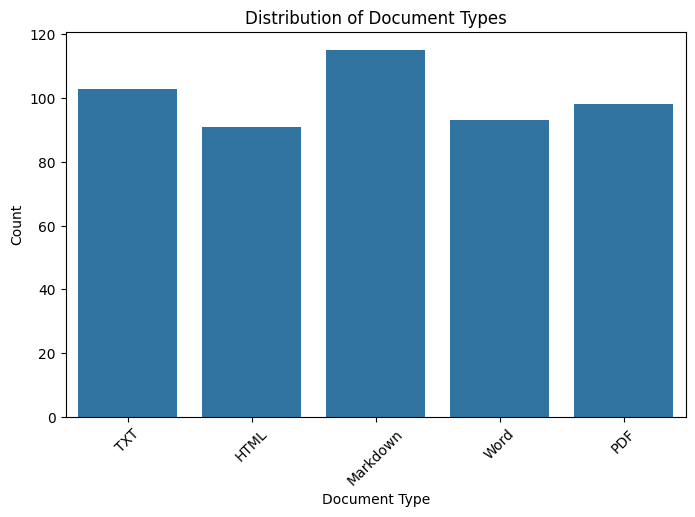

In [29]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="doc_type")

plt.title("Distribution of Document Types")
plt.xlabel("Document Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

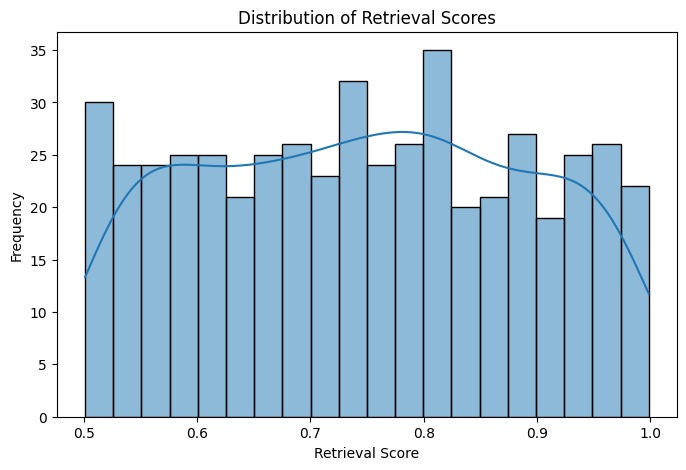

In [30]:
plt.figure(figsize=(8,5))

sns.histplot(df["retrieval_score"], bins=20, kde=True)

plt.title("Distribution of Retrieval Scores")
plt.xlabel("Retrieval Score")
plt.ylabel("Frequency")
plt.show()

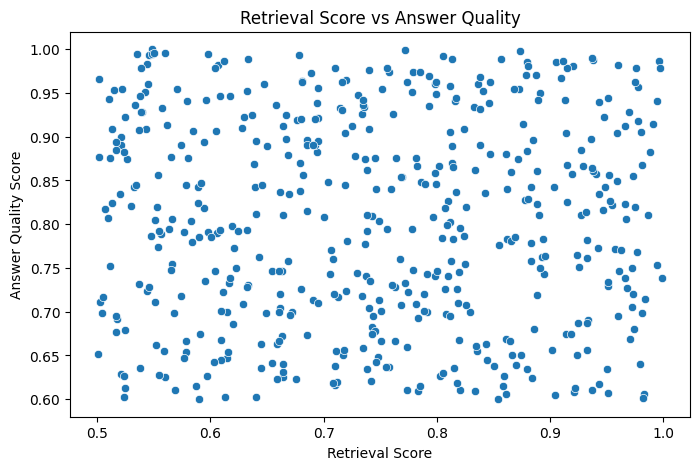

In [31]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="retrieval_score",
    y="answer_quality_score"
)

plt.title("Retrieval Score vs Answer Quality")
plt.xlabel("Retrieval Score")
plt.ylabel("Answer Quality Score")
plt.show()

# EDA Observations

1. The dataset contains different document formats.
2. Query types represent different academic question categories.
3. Retrieval scores indicate the relevance of retrieved document chunks.
4. Answer quality scores provide an indication of generated answer quality.
5. The relationship between retrieval scores and answer quality
   can be explored to understand retrieval effectiveness.